# K-Nearest Neighbors from Scratch

A NumPy implementation of KNN classification, demonstrated on the Wine dataset. The distance calculation, neighbor search, voting, standardization, and accuracy calculation are implemented directly.

Scikit-learn supplies the dataset, stratified split/fold indices, and evaluation displays. Its KNN classifier is not used.

**Run:** Install `requirements.txt`, then run this notebook from top to bottom. The dataset is included with scikit-learn; no CSV download is needed.

## 1. Load the data and create a fixed train/test split

In [1]:
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42
wine = load_wine()
X, y = wine.data, wine.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y
)

print(f"Dataset: {X.shape[0]} samples, {X.shape[1]} features, {len(wine.target_names)} classes")
print(f"Training: {len(X_train)} samples | Test: {len(X_test)} samples")
print("Training class counts:", np.bincount(y_train))
print("Test class counts:", np.bincount(y_test))

Dataset: 178 samples, 13 features, 3 classes
Training: 124 samples | Test: 54 samples
Training class counts: [41 50 33]
Test class counts: [18 21 15]


## 2. Validate inputs and implement Euclidean distance

For vectors $a$ and $b$, Euclidean distance is $\sqrt{\sum_j(a_j-b_j)^2}$.

The functions check array shapes, finite numerical features, matching sample/label counts, and the valid range of `k`. Public functions receive their data explicitly rather than depending on notebook variables.

In [2]:
def feature_matrix(values, name):
    """Convert features to a finite, nonempty 2D floating-point array."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 2 or 0 in array.shape:
        raise ValueError(f"{name} must be a nonempty 2D feature matrix.")
    if not np.isfinite(array).all():
        raise ValueError(f"{name} must contain only finite values.")
    return array


def validate_training_data(k, train_set, train_labels):
    """Validate the stored examples, labels, and neighbor count."""
    train = feature_matrix(train_set, "train_set")
    labels = np.asarray(train_labels)
    if labels.ndim != 1 or len(labels) != len(train):
        raise ValueError("train_labels must be 1D with one label per training row.")
    if isinstance(k, (bool, np.bool_)) or not isinstance(k, (int, np.integer)):
        raise ValueError("k must be an integer.")
    if not 1 <= k <= len(train):
        raise ValueError("k must be between 1 and the number of training rows.")
    return train, labels


def euclidean_distance(r1, r2):
    """Return the Euclidean distance between two equal-length feature vectors."""
    first, second = np.asarray(r1, dtype=float), np.asarray(r2, dtype=float)
    if first.ndim != 1 or second.ndim != 1 or first.shape != second.shape or first.size == 0:
        raise ValueError("Inputs must be nonempty 1D vectors with matching lengths.")
    if not np.isfinite(first).all() or not np.isfinite(second).all():
        raise ValueError("Feature vectors must contain only finite values.")
    return float(np.sqrt(np.sum((first - second) ** 2)))

## 3. Implement neighbor search and voting

For each query, calculate distances to every training row with NumPy, sort by distance, and count the labels among the nearest `k` examples.

**Tie policy:** If class vote counts tie, choose the tied class whose nearest representative is closest. If distances also tie, preserve training-row order using a stable sort. Odd `k` can still produce tied votes in multiclass classification.

The batch function validates the training data once and then predicts one query at a time, avoiding a full test-by-training distance matrix.

In [3]:
def _predict_one(k, train, query, labels):
    """Predict one row after validation; vectorize distances over training rows."""
    distances = np.sqrt(np.sum((train - query) ** 2, axis=1))
    neighbor_indices = np.argsort(distances, kind="stable")[:k]
    neighbor_labels = labels[neighbor_indices]
    vote_counts = Counter(neighbor_labels)
    most_votes = max(vote_counts.values())

    # Neighbors are distance-ordered: the first tied class has the nearest representative.
    return next(label for label in neighbor_labels if vote_counts[label] == most_votes)


def knn(k, train_set, test_instance, train_labels):
    """Predict a class for one feature vector using uniform neighbor votes."""
    train, labels = validate_training_data(k, train_set, train_labels)
    query = np.asarray(test_instance, dtype=float)
    if query.ndim != 1 or query.size != train.shape[1]:
        raise ValueError("test_instance must be a 1D vector matching the training features.")
    if not np.isfinite(query).all():
        raise ValueError("test_instance must contain only finite values.")
    return _predict_one(k, train, query, labels)


def get_predictions(k, train_set, test_set, train_labels):
    """Predict labels for a nonempty batch, without using global data variables."""
    train, labels = validate_training_data(k, train_set, train_labels)
    test = feature_matrix(test_set, "test_set")
    if test.shape[1] != train.shape[1]:
        raise ValueError("Training and test data must have the same feature count.")
    return np.asarray([_predict_one(k, train, row, labels) for row in test])


def evaluate(predictions, actual_labels):
    """Calculate accuracy from the two supplied nonempty label vectors."""
    predicted, actual = np.asarray(predictions), np.asarray(actual_labels)
    if predicted.ndim != 1 or actual.ndim != 1:
        raise ValueError("Predictions and actual labels must be 1D.")
    if predicted.size == 0 or predicted.shape != actual.shape:
        raise ValueError("Predictions and actual labels must have equal, nonzero lengths.")
    return float(np.mean(predicted == actual))

## 4. Standardize features with NumPy

KNN is sensitive to measurement scales. Standardization transforms each feature using $z=(x-\mu)/\sigma$, with the mean and population standard deviation calculated **only from the current training partition**.

Use a scale of 1 for constant training features to avoid division by zero. Apply the training statistics unchanged to validation or test rows.

In [4]:
def fit_standardizer(training_features):
    """Learn per-feature means and scales from training data only."""
    train = feature_matrix(training_features, "training_features")
    mean = train.mean(axis=0)
    scale = train.std(axis=0, ddof=0)
    scale = np.where(scale == 0, 1.0, scale)
    return mean, scale


def standardize(features, mean, scale):
    """Transform a feature matrix using previously learned statistics."""
    values = feature_matrix(features, "features")
    mean, scale = np.asarray(mean, dtype=float), np.asarray(scale, dtype=float)
    expected_shape = (values.shape[1],)
    if mean.shape != expected_shape or scale.shape != expected_shape:
        raise ValueError("mean and scale must contain one value per feature.")
    if not np.isfinite(mean).all() or not np.isfinite(scale).all() or np.any(scale <= 0):
        raise ValueError("Means must be finite and scales must be finite and positive.")
    return (values - mean) / scale

## 5. Choose k using cross-validation on the training set

Compare the original candidates **3, 5, and 7** using five stratified folds within the 124 training examples. Each fold learns its own scaling statistics from its training rows. Validation rows never contribute to fitting the scaler.

Select the candidate with the highest mean validation accuracy. If means tie exactly, choose the smaller `k`. The test scores are not used in this selection.

In [5]:
k_values = [3, 5, 7]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = list(cv.split(X_train, y_train))
cv_scores = {}

for k in k_values:
    fold_scores = []
    for fit_indices, validation_indices in folds:
        fold_train = X_train[fit_indices]
        fold_validation = X_train[validation_indices]
        fold_mean, fold_scale = fit_standardizer(fold_train)

        fold_predictions = get_predictions(
            k,
            standardize(fold_train, fold_mean, fold_scale),
            standardize(fold_validation, fold_mean, fold_scale),
            y_train[fit_indices],
        )
        fold_scores.append(evaluate(fold_predictions, y_train[validation_indices]))
    cv_scores[k] = np.asarray(fold_scores)

cv_means = np.array([cv_scores[k].mean() for k in k_values])
cv_stds = np.array([cv_scores[k].std(ddof=1) for k in k_values])
best_k = min(k_values, key=lambda k: (-cv_scores[k].mean(), k))

for k, mean_accuracy, std_accuracy in zip(k_values, cv_means, cv_stds):
    print(f"k={k}: mean validation accuracy = {mean_accuracy:.2%}, fold SD = {std_accuracy:.2%}")
print(f"Selected k: {best_k}")

k=3: mean validation accuracy = 95.97%, fold SD = 4.00%
k=5: mean validation accuracy = 96.80%, fold SD = 3.35%
k=7: mean validation accuracy = 96.80%, fold SD = 3.35%
Selected k: 5


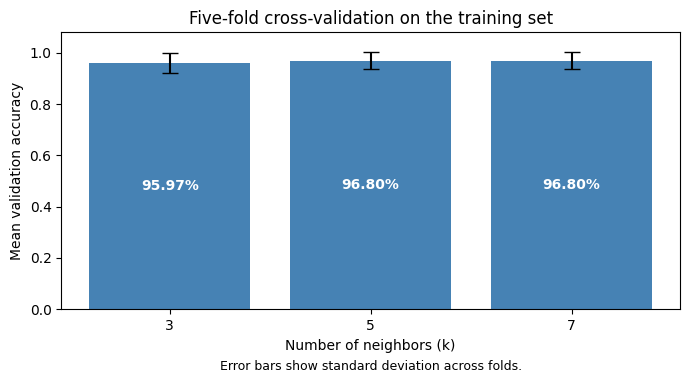

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([str(k) for k in k_values], cv_means, yerr=cv_stds, capsize=6, color="steelblue")
ax.bar_label(bars, labels=[f"{score:.2%}" for score in cv_means], label_type="center", color="white", fontweight="bold")
ax.set(xlabel="Number of neighbors (k)", ylabel="Mean validation accuracy",
       title="Five-fold cross-validation on the training set", ylim=(0, 1.08))
ax.text(0.5, -0.22, "Error bars show standard deviation across folds.",
        transform=ax.transAxes, ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## 6. Evaluate the selected configuration

Fit scaling on all 124 training rows, transform the 54 test rows with those statistics, and evaluate the selected `k`. KNN stores training examples; it has no weight-training step.

Accuracy and per-class metrics describe this fixed split. The same split appeared in the earlier exploratory notebook, so this is an educational benchmark rather than a new independent confirmation dataset.

In [7]:
training_mean, training_scale = fit_standardizer(X_train)
X_train_scaled = standardize(X_train, training_mean, training_scale)
X_test_scaled = standardize(X_test, training_mean, training_scale)

test_predictions = get_predictions(best_k, X_train_scaled, X_test_scaled, y_train)
test_accuracy = evaluate(test_predictions, y_test)
correct_predictions = int(np.sum(test_predictions == y_test))

print(f"Selected k: {best_k}")
print(f"Test accuracy: {test_accuracy:.2%} ({correct_predictions}/{len(y_test)} correct)")
print()
print(classification_report(y_test, test_predictions, target_names=wine.target_names, zero_division=0))

Selected k: 5
Test accuracy: 94.44% (51/54 correct)

              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        18
     class_1       1.00      0.86      0.92        21
     class_2       0.83      1.00      0.91        15

    accuracy                           0.94        54
   macro avg       0.94      0.95      0.94        54
weighted avg       0.95      0.94      0.94        54



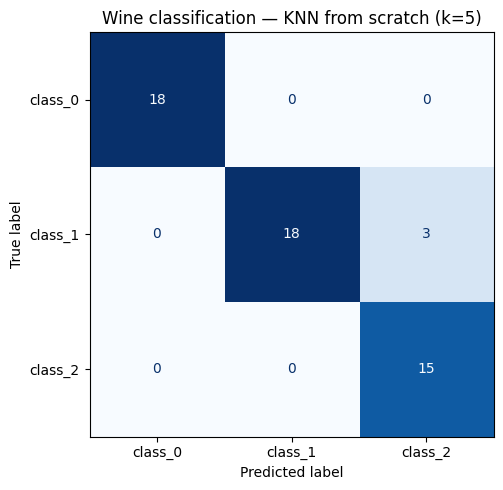

In [8]:
matrix = confusion_matrix(y_test, test_predictions, labels=np.arange(len(wine.target_names)))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matrix, display_labels=wine.target_names).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title(f"Wine classification — KNN from scratch (k={best_k})")
plt.tight_layout()
plt.show()

## 7. Predict a single sample

Use the same feature order and training statistics for new samples. This example reuses the first test row to demonstrate the function interface.

In [9]:
sample_scaled = standardize(X_test[:1], training_mean, training_scale)[0]
predicted_class = knn(best_k, X_train_scaled, sample_scaled, y_train)
print("Predicted class:", wine.target_names[predicted_class])
print("Actual class:", wine.target_names[y_test[0]])

Predicted class: class_0
Actual class: class_0


## Implementation notes

- Distances are vectorized over training rows; queries are processed one at a time.
- Full sorting makes prediction cost roughly $O(nd+n\log n+k)$ per query, where $n$ is the number of training rows and $d$ is the feature count.
- Counting votes once avoids repeatedly scanning the neighbor list.
- Deterministic ties favor the nearest representative, then training-row order for equal distances. A different tie policy may produce different predictions.
- Functions accept finite, nonempty feature arrays and 1D class-label arrays; `k` must be an integer between 1 and the training-set size.

## Dataset

The [Wine dataset](https://archive.ics.uci.edu/dataset/109/wine) contains 178 samples, 13 numerical features, and three wine classes. It is available directly through [scikit-learn's `load_wine`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html).

This is a classification task based on chemical measurements, not wine-quality rating prediction.

## References:
[TowardsDataScience](https://towardsdatascience.com/lets-make-a-knn-classifier-from-scratch-e73c43da346d/)

[NYCDataScience](https://nycdatascience.com/blog/student-works/machine-learning/knn-classifier-from-scratch-numpy-only/)

[Medium](https://medium.com/@lope.ai/knn-classifier-from-scratch-with-numpy-python-5c436e26a228)

[GitHub](https://github.com/mavaladezt/kNN-from-Scratch/blob/master/knn.py)

[Kaggle](https://www.kaggle.com/code/sayelabualigah/knn-from-scratch-using-numpy)

[W3Schools(matplotlib)](https://www.w3schools.com/python/matplotlib_bars.asp)

### Additional documentation

- [Feature scaling and KNN](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html)
- [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html)
- [NumPy documentation](https://numpy.org/doc/stable/)